Task 1:

Random Forest Feature Importance

The purpose is to identify which features have the greatest overall influence on the predictions with the Random Forest model that was selected from Week 4.

In [1]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier

#Load in the Dataset
df = pd.read_csv("community_risk_screening_train.csv")

#Select the Features
feature_columns = [
    "age_at_screening",
    "region",
    "housing_status",
    "prior_crisis_events_12mo",
    "phq2_score",
    "substance_use_flag",
    "primary_support_type",
    "days_since_last_contact"
]

#Separate Features and Target
x = df[feature_columns]
y = df["crisis_within_90_days"]


#Recreate Same Training, Validation, and Test Split
x_train, x_temp, y_train, y_temp = train_test_split(
    x, y, test_size=0.30, random_state=42, stratify=y
)

x_val, x_test, y_val, y_test = train_test_split(
    x_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

#Define Numeric and Categorical Features
numeric_features = [
    "age_at_screening",
    "prior_crisis_events_12mo",
    "phq2_score",
    "days_since_last_contact"
]

categorical_features = [
    "region",
    "housing_status",
    "substance_use_flag",
    "primary_support_type"
]

#Preprocess Numeric Features Using Median Imputation
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

#Preprocess Categorical Features Using Frequent Imputation and One Hot Encoding
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

#Combine Steps
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

#Recrate Random Forest Model
best_rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=100,
        max_depth=None,
        class_weight="balanced",
        random_state=42
    ))
])

#Train the Model Using the Training Data
best_rf_pipeline.fit(x_train, y_train)

#Get Feature Importance From Train Model
importances = best_rf_pipeline.named_steps["model"].feature_importances_

#Get Feature Names After Preprocessing
feature_names = best_rf_pipeline.named_steps["preprocessor"].get_feature_names_out()

#Create a Table
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

#Sort the Features From Highest to Lowest
feature_importance = feature_importance.sort_values(
    by="Importance", ascending=False
)

#Display
print("Features:", x.columns.tolist())
print("\nTarget:", y.name)
print("Training rows:", len(x_train))
print("Validation rows:", len(x_val))
print("Test rows:", len(x_test))
print("Random Forest Model Successfully Trained!")
print(feature_importance.head(10))

Features: ['age_at_screening', 'region', 'housing_status', 'prior_crisis_events_12mo', 'phq2_score', 'substance_use_flag', 'primary_support_type', 'days_since_last_contact']

Target: crisis_within_90_days
Training rows: 1680
Validation rows: 360
Test rows: 360
Random Forest Model Successfully Trained!
                                           Feature  Importance
2                              numeric__phq2_score    0.235787
3                 numeric__days_since_last_contact    0.209390
0                        numeric__age_at_screening    0.177051
1                numeric__prior_crisis_events_12mo    0.141711
14  categorical__primary_support_type_case_manager    0.060262
9        categorical__housing_status_stable_housed    0.050098
5                   categorical__region_Gulf Coast    0.012707
12           categorical__substance_use_flag_False    0.012059
13            categorical__substance_use_flag_True    0.011733
6                categorical__region_Inland Valley    0.010647


**Interpretability Requirements and User Needs**

1. Explanation Requirements

Based on Amara’s feedback, the model output needs to provide three main things for the caseworkers:
Risk Score: Show the estimated risk of a crisis within the next 90 day timeframe
Reason Behind the Score: Shows the main factors that contributed to the model’s prediction
Confidence in the Results: Provide information about confidence so caseworkers can understand the limitations of the prediction and use their own professional judgement
Additional requirements may include:
Easy to understand labels
Show the PHQ-2 score and the number of days since the client’s last contact
Add a simple explanation next to Client Age to show the caseworkers that age is just one of the factors the model looks at
Make it clear when the confidence information is not available yet

2. Anti-Patterns to Avoid

Based on Amara’s feedback, the following should be avoided:
Using technical terms that caseworkers may not understand
Showing the age without any explanation of why it is included
Showing feature labels without any actual values of the client
Displaying the confidence information without explaining whether the information is available or validated
Making it seem that the model judgment is to replace professional judgment

3. Preferred Explanation Format

Simple and organized output that is easy to read
Preferred format should have:
Risk score and risk classification at the top
Main factors that are contributing to the prediction underneath the risk score
The actual values for the PHQ-2 score and time since last contact
Client age and a short explanation directly underneath it
A confidence section that clearly explains when the confidence information is available or not
An important reminder to remind the caseworkers that the model is here to support decisions, not replace professional judgement

4. Summary

The goal of this is to help caseworkers understand the model’s predictions and the information behind them. To help them understand that the model is here to support caseworkers in making informed decisions and not replace any professional judgement. The explanations need to be simple and quick to understand, with relevant client information that clearly communicates the results.

**MOCKUP**
Community Health Risk Screening

Risk Score

[Risk Score]%
The estimate of likelihood of a crisis within the next 90 days

Screening Results
[ High Risk / Low Risk ]
Uses the 0.30 threshold Random Forest Model to classify risk


Main Factors to Consider

Mood Screen Score
PHQ-2 Score
Time Since Last Contact
Number of days since last contact
Client Age
Age
Age is one of the factor considered by the model and should not be used by itself to determine a client’s risk factor
Primary Support Type: Case Manager
The model considered whether a case manager was recorded as the client’s primary support type when calculating the risk prediction


Confidence Results
Not yet available – Confidence information is still being evaluated

When the confidence information is unavailable, caseworkers should review the client’s records and use their own professional judgement before making any decisions.

*Caseworkers should always use their professional judgement when reviewing the screening results and should not assume the prediction is for certain!

Important Reminder
The screening result is intended to help support caseworker’s decisions and does not replace professional judgement. It is important to review the client’s information and circumstances before deciding on the next steps!


Task 2:

**SHAP Local Hypothesis**

Looking back on my previous feature importance results, I expect the PHQ-2 score to have the strongest influence on the high risk prediction since it had the highest overall feature importance. Not only that I also expect days since last contact and age at screening to also have an influence on the predictions. Once I get the results I will compare these expectation with the actual SHAPto see whether the individual prediction follows the same pattern.

In [17]:
import shap

#Get Prediction Probabilities for the Validation Data
val_probabilities = best_rf_pipeline.predict_proba(x_val)[:, 0]

#Apply the Week 4 Threshold
val_predictions = (val_probabilities >= 0.30).astype(int)

#Find High and Low Risk Validation Records
high_risk_positions = [
    i for i, prediction in enumerate(val_predictions) if prediction == 1
]

low_risk_positions = [
    i for i, prediction in enumerate(val_predictions) if prediction == 0
]

print("High Risk Records:", len(high_risk_positions))
print("Low Risk Records:", len(low_risk_positions))

High Risk Records: 79
Low Risk Records: 281


In [18]:
#Select One High and One Low Risk Validation Record
high_risk_index = high_risk_positions[0]
low_risk_index = low_risk_positions[0]

print("High Risk Probability:", val_probabilities[high_risk_index])
print("Low Risk Probability:", val_probabilities[low_risk_index])

High Risk Probability: 0.35
Low Risk Probability: 0.03


In [19]:
#Select the Highest and Lowest Risk Validation Records
high_risk_index = max(high_risk_positions, key=lambda i: val_probabilities[i])
low_risk_index = min(low_risk_positions, key=lambda i: val_probabilities[i])

print("High Risk Crisis Probability:", val_probabilities[high_risk_index])
print("Low Risk Crisis Probability:", val_probabilities[low_risk_index])

High Risk Crisis Probability: 1.0
Low Risk Crisis Probability: 0.0


In [20]:
#Transform Validation Data Using Fitted Preprocessing Pipeline
x_val_transform = best_rf_pipeline.named_steps["preprocessor"].transform(x_val)

#Get Trained Random Forest Model
rf_model = best_rf_pipeline.named_steps["model"]

#Convert Sparse Data to a Regular Array if Needed
if hasattr(x_val_transform, "toarray"):
    x_val_transformed = x_val_transform.toarray()

#Get Transformed Feature Names
feature_names = best_rf_pipeline.named_steps["preprocessor"].get_feature_names_out()

print("Transformed Validation Shape:", x_val_transform.shape)
print("Number of Feature Names:", len(feature_names))

Transformed Validation Shape: (360, 19)
Number of Feature Names: 19


In [11]:
#Create SHAP TreeExplainer for Random Forest Model
explainer = shap.TreeExplainer(rf_model)

#Calculate SHAP Values for Validation Data
shap_values = explainer.shap_values(x_val_transform)

print("SHAP Values Calculated Successfully!")
print("SHAP Output Type:", type(shap_values))
print("SHAP Values Shape:", shap_values.shape)

SHAP Values Calculated Successfully!
SHAP Output Type: <class 'numpy.ndarray'>
SHAP Values Shape: (360, 19, 2)


In [21]:
#Select SHAP Value for Crisis Class
shap_values_crisis = shap_values[:, :, 0]

#Select High and Low Risk Examples
high_risk_shap = shap_values_crisis[high_risk_index]
low_risk_shap = shap_values_crisis[low_risk_index]

print("High Risk SHAP Shape:", high_risk_shap.shape)
print("Low Risk SHAP Shape:", low_risk_shap.shape)

High Risk SHAP Shape: (19,)
Low Risk SHAP Shape: (19,)


In [22]:
#Create High Risk Explanation Table
high_risk_explanation = pd.DataFrame({
    "Feature": feature_names,
    "SHAP Value": high_risk_shap
})

high_risk_explanation["Absolute SHAP Value"] = high_risk_explanation["SHAP Value"].abs()

high_risk_explanation = high_risk_explanation.sort_values(
    by = "Absolute SHAP Value",
    ascending = False
)

print("High-Risk Prediction Explanation:")
display(high_risk_explanation.head(10))


#Create Low Risk Explanation Table
low_risk_explanation = pd.DataFrame({
    "Feature": feature_names,
    "SHAP Value": low_risk_shap
})

low_risk_explanation["Absolute SHAP Value"] = low_risk_explanation["SHAP Value"].abs()

low_risk_explanation = low_risk_explanation.sort_values(
    by = "Absolute SHAP Value",
    ascending = False
)

print("Low-Risk Prediction Explanation:")
display(low_risk_explanation.head(10))

High-Risk Prediction Explanation:


,Feature,SHAP Value,Absolute SHAP Value
2,numeric__phq2_score,0.213023,0.213023
3,numeric__days_since_last_contact,0.178353,0.178353
14,categorical__primary_support_type_case_manager,0.048573,0.048573
9,categorical__housing_status_stable_housed,0.044797,0.044797
18,categorical__primary_support_type_peer_support,0.018363,0.018363
10,categorical__housing_status_transitional,0.014565,0.014565
1,numeric__prior_crisis_events_12mo,-0.012811,0.012811
5,categorical__region_Gulf Coast,0.006620,0.006620
12,categorical__substance_use_flag_False,-0.005248,0.005248
0,numeric__age_at_screening,-0.004940,0.004940


Low-Risk Prediction Explanation:


,Feature,SHAP Value,Absolute SHAP Value
2,numeric__phq2_score,-0.160232,0.160232
3,numeric__days_since_last_contact,-0.071138,0.071138
14,categorical__primary_support_type_case_manager,-0.068190,0.068190
1,numeric__prior_crisis_events_12mo,-0.049307,0.049307
0,numeric__age_at_screening,-0.042123,0.042123
9,categorical__housing_status_stable_housed,-0.034962,0.034962
6,categorical__region_Inland Valley,-0.020594,0.020594
5,categorical__region_Gulf Coast,-0.009415,0.009415
11,categorical__housing_status_unstable_or_unhoused,-0.008192,0.008192
18,categorical__primary_support_type_peer_support,-0.007085,0.007085


In [29]:
#Display Original Feature Values for Both Example

print("High Risk Example:")
display(x_val.iloc[[high_risk_index]])

print("High Risk Probability:", val_probabilities[high_risk_index])

print("Low Risk Example:")
display(x_val.iloc[[low_risk_index]])

print("Low Risk Probability:", val_probabilities[low_risk_index])

High Risk Example:


,age_at_screening,region,housing_status,prior_crisis_events_12mo,phq2_score,substance_use_flag,primary_support_type,days_since_last_contact
995,54.0,Gulf Coast,transitional,6.0,6.0,True,peer_support,730.0


High Risk Probability: 1.0
Low Risk Example:


,age_at_screening,region,housing_status,prior_crisis_events_12mo,phq2_score,substance_use_flag,primary_support_type,days_since_last_contact
244,56.0,Inland Valley,stable_housed,7.0,2.01,False,NaN,428.0


Low Risk Probability: 0.0


In [27]:
#Check Order of Model's Prediction Class
print("Model Classes:", rf_model.classes_)

Model Classes: ['crisis' 'no_crisis']


**SHAP Reason Codes**

The SHAP reason codes will help translate the model's predictions into a more understandable explanation so that the caseworkers can interpret it more easier and identify which features contributed most to the high risk and low risk predictions.

In [31]:
#Create High Risk Reason Code
high_risk_reasons = high_risk_explanation.head(3).copy()

high_risk_reasons["Feature Value"] = [
    x_val_transform[high_risk_index, list(feature_names).index(feature)]
    for feature in high_risk_reasons["Feature"]
]

high_risk_reasons["Direction"] = high_risk_reasons["SHAP Value"].apply(
    lambda value: "Increased Crisis Prediction" if value > 0
    else "Decreased Crisis Prediction"
)

print("High-Risk Reason Codes:")
display(high_risk_reasons[["Feature", "Feature Value", "SHAP Value", "Direction"]])


#Create Low Risk Reason Codes
low_risk_reasons = low_risk_explanation.head(3).copy()

low_risk_reasons["Feature Value"] = [
    x_val_transform[low_risk_index, list(feature_names).index(feature)]
    for feature in low_risk_reasons["Feature"]
]

low_risk_reasons["Direction"] = low_risk_reasons["SHAP Value"].apply(
    lambda value: "Increased Crisis Prediction" if value > 0
    else "Decreased Crisis Prediction"
)

print("Low-Risk Reason Codes:")
display(low_risk_reasons[["Feature", "Feature Value", "SHAP Value", "Direction"]])

High-Risk Reason Codes:


,Feature,Feature Value,SHAP Value,Direction
2,numeric__phq2_score,6.0,0.213023,Increased Crisis Prediction
3,numeric__days_since_last_contact,730.0,0.178353,Increased Crisis Prediction
14,categorical__primary_support_type_case_manager,0.0,0.048573,Increased Crisis Prediction


Low-Risk Reason Codes:


,Feature,Feature Value,SHAP Value,Direction
2,numeric__phq2_score,2.01,-0.160232,Decreased Crisis Prediction
3,numeric__days_since_last_contact,428.00,-0.071138,Decreased Crisis Prediction
14,categorical__primary_support_type_case_manager,1.00,-0.068190,Decreased Crisis Prediction


In [30]:
#Check Case Manager Feature Values
case_manager_index = list(feature_names).index(
    "categorical__primary_support_type_case_manager"
)

print("High Risk Case Manager Value:",
      x_val_transform[high_risk_index, case_manager_index])

print("Low Risk Case Manager Value:",
      x_val_transform[low_risk_index, case_manager_index])

High Risk Case Manager Value: 0.0
Low Risk Case Manager Value: 1.0


**Reason Code Results**

The reason codes help explain how the individual features influence the model's predictions. The positive SHAP values indicate that the feature pushes the prediction toward the crisis class, while the negative SHAP values push the prediction away from the crisis class. Showing the actual feature values along with their SHAP values helps the caseworkers have a better understanding which features had the most influence on each prediction. However, these explanations shows how the model uses the features to make predictions and do not mean that they directly cause a crisis.

In [40]:
#Create a Reusable Function to Generate Reason Codes
def generate_reason_codes(input_data):

    #Get the Crisis Class Index
    crisis_class_index = list(rf_model.classes_).index("crisis")

    #Generate the Crisis Probability
    crisis_probability = best_rf_pipeline.predict_proba(input_data)[0][crisis_class_index]

    #Apply Week 4 Random Model Threshold
    if crisis_probability >= 0.30:
        prediction = "High Risk"
    else:
        prediction = "Low Risk"

    #Transform the Input Using the Fitted Preprocessor
    transformed_data = best_rf_pipeline.named_steps["preprocessor"].transform(input_data)

    if hasattr(transformed_data, "toarray"):
        transformed_data = transformed_data.toarray()

    #Calculate SHAP Values
    new_shap_values = explainer.shap_values(transformed_data)

    #Select SHAP Values for the Crisis Class
    if isinstance(new_shap_values, list):
        crisis_shap_values = new_shap_values[crisis_class_index][0]
    else:
        crisis_shap_values = new_shap_values[0, :, crisis_class_index]

    #Create Reason Code Table
    reason_codes = pd.DataFrame({
        "Feature": feature_names,
        "Feature Value": transformed_data[0],
        "SHAP Value": crisis_shap_values
    })

    #Rank Features by There Absolute SHAP Values
    reason_codes["Absolute SHAP Value"] = reason_codes["SHAP Value"].abs()

    #Identify Whether Each Feature Increased or Decreased the Crisis Prediction
    reason_codes["Direction"] = reason_codes["SHAP Value"].apply(
        lambda value: "Increased Risk" if value > 0
        else "Decreased Risk"
    )

    #Return the Top Three Reason Codes
    reason_codes = reason_codes.sort_values(
        by="Absolute SHAP Value",
        ascending=False
    ).head(3)

    #Replace Technical Feature Terms With Labels Easy to Read
    reason_codes["Feature"] = reason_codes["Feature"].replace({
        "numeric__phq2_score": "Mood Screen Score (PHQ-2)",
        "numeric__days_since_last_contact": "Time Since Last Contact",
        "numeric__age_at_screening": "Client Age",
        "numeric__prior_crisis_events_12mo": "Prior Crisis Events",
      "categorical__primary_support_type_case_manager": "Primary Support Type: Case Manager"
    })

    #Add Original Client Values
    reason_codes["Client Value"] = reason_codes["Feature"].map({
        "Mood Screen Score (PHQ-2)": input_data["phq2_score"].iloc[0],
        "Time Since Last Contact": input_data["days_since_last_contact"].iloc[0],
        "Client Age": input_data["age_at_screening"].iloc[0],
        "Prior Crisis Events": input_data["prior_crisis_events_12mo"].iloc[0],
        "Primary Support Type: Case Manager": input_data["primary_support_type"].iloc[0]
    })

    #Show Results
    return prediction, crisis_probability, reason_codes, input_data


In [44]:
#Testing High Risk
prediction, probability, reasons, client_data = generate_reason_codes(
    x_val.iloc[[high_risk_index]]
)

print("Risk Classification:", prediction)
print("Risk Score:", f"{probability:.2%}")

print("\nMain Factors to Consider:")
display(reasons[["Feature", "Client Value", "Direction"]])

#Display Client Age and Explanation
print("\nClient Age:")
print("Age:", client_data["age_at_screening"].iloc[0])
print(
    "Age is one of the factors considered by the model and should not be used by itself to determine the client's risk factor."
)

#Display Confidence Info
print("\nConfidence Results:")
print("Not Yet Available – Confidence information is still being evaluated.")

print(
    "When the confidence information is unavailable, caseworkers should review the client records and use their own professional judgement."
)

print("\nImportant Reminder:")
print(
    "The screening result only supports caseworker decisions and shouldn't replace professional judgement. Caseworkers should review the client's information and circumstances independently before deciding on the next steps."
)

Risk Classification: High Risk
Risk Score: 100.00%

Main Factors to Consider:


,Feature,Client Value,Direction
2,Mood Screen Score (PHQ-2),6.0,Increased Risk
3,Time Since Last Contact,730.0,Increased Risk
14,Primary Support Type: Case Manager,peer_support,Increased Risk



Client Age:
Age: 54.0
Age is one of the factors considered by the model and should not be used by itself to determine the client's risk factor.

Confidence Results:
Not Yet Available – Confidence information is still being evaluated.
When confidence information is unavailable, caseworkers should review the client records and use their own professional judgement.

Important Reminder:
The screening result only supports caseworker decisions and shouldn't replace professional judgement. Caseworkers should review the client's information and circumstances independently before deciding on the next steps.


In [45]:
#Testing Fifth Validation Record
prediction, probability, reasons, client_data = generate_reason_codes(
    x_val.iloc[[4]]
)

print("Risk Classification:", prediction)
print("Risk Score:", f"{probability:.2%}")

print("\nMain Factors to Consider:")
display(reasons[["Feature", "Client Value", "Direction"]])

#Display Client Age and Explanation
print("\nClient Age:")
print("Age:", client_data["age_at_screening"].iloc[0])
print(
    "Age is one of the factors considered by the model and should not be used by itself to determine the client's risk factor."
)

#Display Confidence Info
print("\nConfidence Results:")
print("Not Yet Available – Confidence information is still being evaluated.")

print(
    "When the confidence information is unavailable, caseworkers should review the client records and use their own professional judgement."
)

print("\nImportant Reminder:")
print(
    "The screening result only supports caseworker decisions and shouldn't replace professional judgement. Caseworkers should review the client's information and circumstances independently before deciding on the next steps."
)

Risk Classification: Low Risk
Risk Score: 20.00%

Main Factors to Consider:


,Feature,Client Value,Direction
0,Client Age,31.0,Decreased Risk
2,Mood Screen Score (PHQ-2),3.63,Decreased Risk
14,Primary Support Type: Case Manager,peer_support,Increased Risk



Client Age:
Age: 31.0
Age is one of the factors considered by the model and should not be used by itself to determine the client's risk factor.

Confidence Results:
Not Yet Available – Confidence information is still being evaluated.
When the confidence information is unavailable, caseworkers should review the client records and use their own professional judgement.

Important Reminder:
The screening result only supports caseworker decisions and shouldn't replace professional judgement. Caseworkers should review the client's information and circumstances independently before deciding on the next steps.


In [48]:
#Testing Third Validation Record
prediction, probability, reasons, client_data = generate_reason_codes(
    x_val.iloc[[third_index]]
)


print("Risk Classification:", prediction)
print("Risk Score:", f"{probability:.2%}")

print("\nMain Factors to Consider:")
display(reasons[["Feature", "Client Value", "Direction"]])

#Display Client Age and Explanation
print("\nClient Age:")
print("Age:", client_data["age_at_screening"].iloc[0])
print(
    "Age is one of the factors considered by the model and should not be used by itself to determine the client's risk factor."
)

#Display Confidence Info
print("\nConfidence Results:")
print("Not Yet Available – Confidence information is still being evaluated.")

print(
    "When the confidence information is unavailable, caseworkers should review the client records and use their own professional judgement."
)

print("\nImportant Reminder:")
print(
    "The screening result only supports caseworker decisions and shouldn't replace professional judgement. Caseworkers should review the client's information and circumstances independently before deciding on the next steps."
)

Risk Classification: Low Risk
Risk Score: 3.00%

Main Factors to Consider:


,Feature,Client Value,Direction
2,Mood Screen Score (PHQ-2),2.56,Decreased Risk
3,Time Since Last Contact,262.0,Decreased Risk
0,Client Age,60.0,Decreased Risk



Client Age:
Age: 60.0
Age is one of the factors considered by the model and should not be used by itself to determine the client's risk factor.

Confidence Results:
Not Yet Available – Confidence information is still being evaluated.
When the confidence information is unavailable, caseworkers should review the client records and use their own professional judgement.

Important Reminder:
The screening result only supports caseworker decisions and shouldn't replace professional judgement. Caseworkers should review the client's information and circumstances independently before deciding on the next steps.


**SHAP Feature Summary**

The local SHAP explanations show how individual features contribute to specific predictions. The global SHAP summary will help identify which features have the greatest overall influence across the validation dataset.

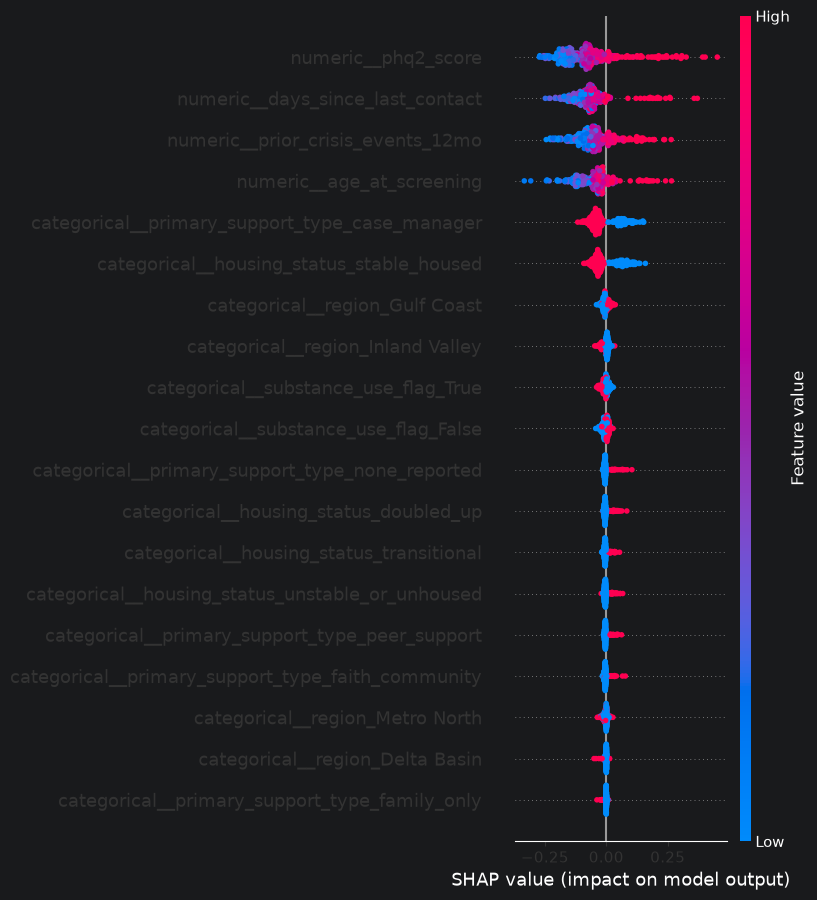

In [26]:
#Create Global SHAP Summary Plot
shap.summary_plot(
    shap_values_crisis,
    x_val_transform,
    feature_names=feature_names
)

**Global SHAP Summary Results**

The results from the Global SHAP summary plot shows us which features have the greatest influence on the predictions of the Random Forest model with a threshold of 0.30. The three most influential features are PHQ-2 Score, Days Since Last Contact and Prior Crisis Events 12 Mo. Having these three being the most influential to the model suggests that a client's depression screening score, amount of time since their last contact and their previous crisis history plays an important role to the predictions of the model. These findings help show which factors the model relies on the most when trying to predict whether a client may experience a crisis within the next 90 days. But these feature importance does not also mean that these factors directly causes a crisis.

**Comparison with Week 3 Feature Importance**

Comparing the Week 6 SHAP rankings with the feature importance ranking from Week 3. The rankings shifted slightly, but the top two features remained consistent. PHQ-2 score and days since last contact remains the top two features in both results. However, prior crisis events switched from fourth in Week 3 to third in Week 6 and age at screening moved from third to fourth.

Task 3:

In [51]:
#Faithfulness Check - PHQ-2 Perturbation Test
def test_phq2_perturbation(input_data, client_name):

    #Get The Crisis Class Index
    crisis_class_index = list(rf_model.classes_).index("crisis")

    #Get Original Crisis Probability
    original_probability = best_rf_pipeline.predict_proba(
        input_data)[0][crisis_class_index]

    #Calculate Original SHAP Values
    transformed_data = best_rf_pipeline.named_steps["preprocessor"].transform(
        input_data
    )

    if hasattr(transformed_data, "toarray"):
        transformed_data = transformed_data.toarray()

    original_shap = explainer.shap_values(transformed_data)

    if isinstance(original_shap, list):
        crisis_shap = original_shap[crisis_class_index][0]
    else:
        crisis_shap = original_shap[0, :, crisis_class_index]

    #Get PHQ-2 SHAP Value
    phq2_index = list(feature_names).index("numeric__phq2_score")
    phq2_shap_value = crisis_shap[phq2_index]

    #Change PHQ-2 Score to Zero
    modified_data = input_data.copy()
    modified_data["phq2_score"] = 0

    #Get New Crisis Probability
    modified_probability = best_rf_pipeline.predict_proba(
        modified_data
    )[0][crisis_class_index]

    #Calculate the Change in Risk Score
    probability_change = modified_probability - original_probability

    #Determine Expected Direction Base on SHAP
    if phq2_shap_value > 0:
        expected_direction = "Decrease"
    elif phq2_shap_value < 0:
        expected_direction = "Increase"
    else:
        expected_direction = "No Clear Direction"

    #Compare Expected and Actual Results
    if probability_change < -0.000001:
        actual_direction = "Decrease"
    elif probability_change > 0.000001:
        actual_direction = "Increase"
    else:
        actual_direction = "No Change"

    if expected_direction == actual_direction:
        result = "Moved as Expected"
    else:
        result = "Unexpected Result"

    return {
        "Client": client_name,
        "Original PHQ-2": input_data["phq2_score"].iloc[0],
        "PHQ-2 SHAP Value": phq2_shap_value,
        "Original Risk Score": original_probability,
        "Modified Risk Score": modified_probability,
        "Expected Direction": expected_direction,
        "Actual Direction": actual_direction,
        "Result": result
    }

#Run the Results
faithfulness_results = [
    test_phq2_perturbation(
        x_val.iloc[[high_risk_index]],
        "High Risk Example"
    ),
    test_phq2_perturbation(
        x_val.iloc[[4]],
        "Fifth Validation Record"
    ),
    test_phq2_perturbation(
        x_val.iloc[[third_index]],
        "Third Validation Record"
    )
]

faithfulness_table = pd.DataFrame(faithfulness_results)

display(faithfulness_table)

,Client,Original PHQ-2,PHQ-2 SHAP Value,Original Risk Score,Modified Risk Score,Expected Direction,Actual Direction,Result
0,High Risk Example,6.00,0.213023,1.00,0.50,Decrease,Decrease,Moved as Expected
1,Fifth Validation Record,3.63,-0.081573,0.20,0.13,Increase,Decrease,Unexpected Result
2,Third Validation Record,2.56,-0.162236,0.03,0.05,Increase,Increase,Moved as Expected


**Faithfulness Check Results**

The PHQ-2 Score perturbation test was performed on the three validation records. Two of the records showed changes in the risk scores that matched the expected direction based on their SHAP values. The fifth validation record also produced an unexpected results. Its negative PHQ-2 SHAP value suggested that changing the PHQ-2 score to zero would increase the risk. However instead of the risk increasing it decreased from 20% to 13%. This result display a potential inconsistency between the SHAP explanation and the model's response to the feature perturbation.

**Unreliable Explanation**

The fifth validation record show us that there is a potential limitation in the faithfulness of the SHAP explanation. The PHQ-2 SHAP value was a negative, but once setting the PHQ-2 score to zero  caused the predicted risk to decrease from 20% to 13% rather than increase as initially expected. One possible explanation is that Random Forest models combine multiple decision trees to identify complex patterns and relationships between features. When the PHQ-2 score is changed, the record may follow different decision paths across the trees, producing an unexpected change in the final prediction. These findings show us that the caseworkers should treat the SHAP reason codes as supporting information rather than a definitive explanations of a client's risk. It is important that the caseworkers use their own professional judgment instead of solely relying on the SHAP reason codes.

**Usage Guidelines**

If the top SHAP reason code contradicts the information that is documented in the verified case note, the caseworkers should flag the discrepancy for a supervisor to review it before taking actions base on the model's explanation. The caseworkers should verify the information and use their own professional judgment when deciding how to proceed and not only relying on the model.